In [1]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from utils.plots import plot_forecast
from models.lstm import run_lstm
from models.shap import explain_variables

c:\TCC\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Buscando os dados

In [2]:
itub_csv = 'data/itub.csv'

if not os.path.exists(itub_csv):
    itub4_dataset = load_stock(STOCKS["itub"], "itub", force=True)
    itub4_dataset.head(10)

itub4_dataset = pd.read_csv(itub_csv)

In [3]:
itub4_dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 3478 entries, 0 to 3477
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          3478 non-null   str    
 1   itub_close    3478 non-null   float64
 2   itub_high     3478 non-null   float64
 3   itub_low      3478 non-null   float64
 4   itub_open     3478 non-null   float64
 5   itub_volume   3478 non-null   int64  
 6   ibovespa      3477 non-null   float64
 7   vix           3477 non-null   float64
 8   selic_daily   3478 non-null   float64
 9   selic_goal    3478 non-null   float64
 10  ipca          3478 non-null   float64
 11  fx_usd        3478 non-null   float64
 12  gdp           3478 non-null   float64
 13  unemployment  3439 non-null   float64
dtypes: float64(12), int64(1), str(1)
memory usage: 380.5 KB


## ARIMA

In [4]:
train_itub, test_itub = split_temporal(itub4_dataset)
res_itub = run_arima(train_itub, test_itub, "itub")

--- Identificando ordem do ARIMA para ITUB ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=781.961, Time=1.49 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=806.503, Time=0.11 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=799.683, Time=0.09 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=799.827, Time=0.14 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=804.917, Time=0.06 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=803.475, Time=0.21 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=803.471, Time=0.44 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=801.189, Time=0.98 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=806.779, Time=1.06 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=801.479, Time=0.10 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=797.308, Time=0.72 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=802.659, Time=0.61 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=792.074, Time=1.74 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=780.239, Time=0.68 sec


c:\TCC\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


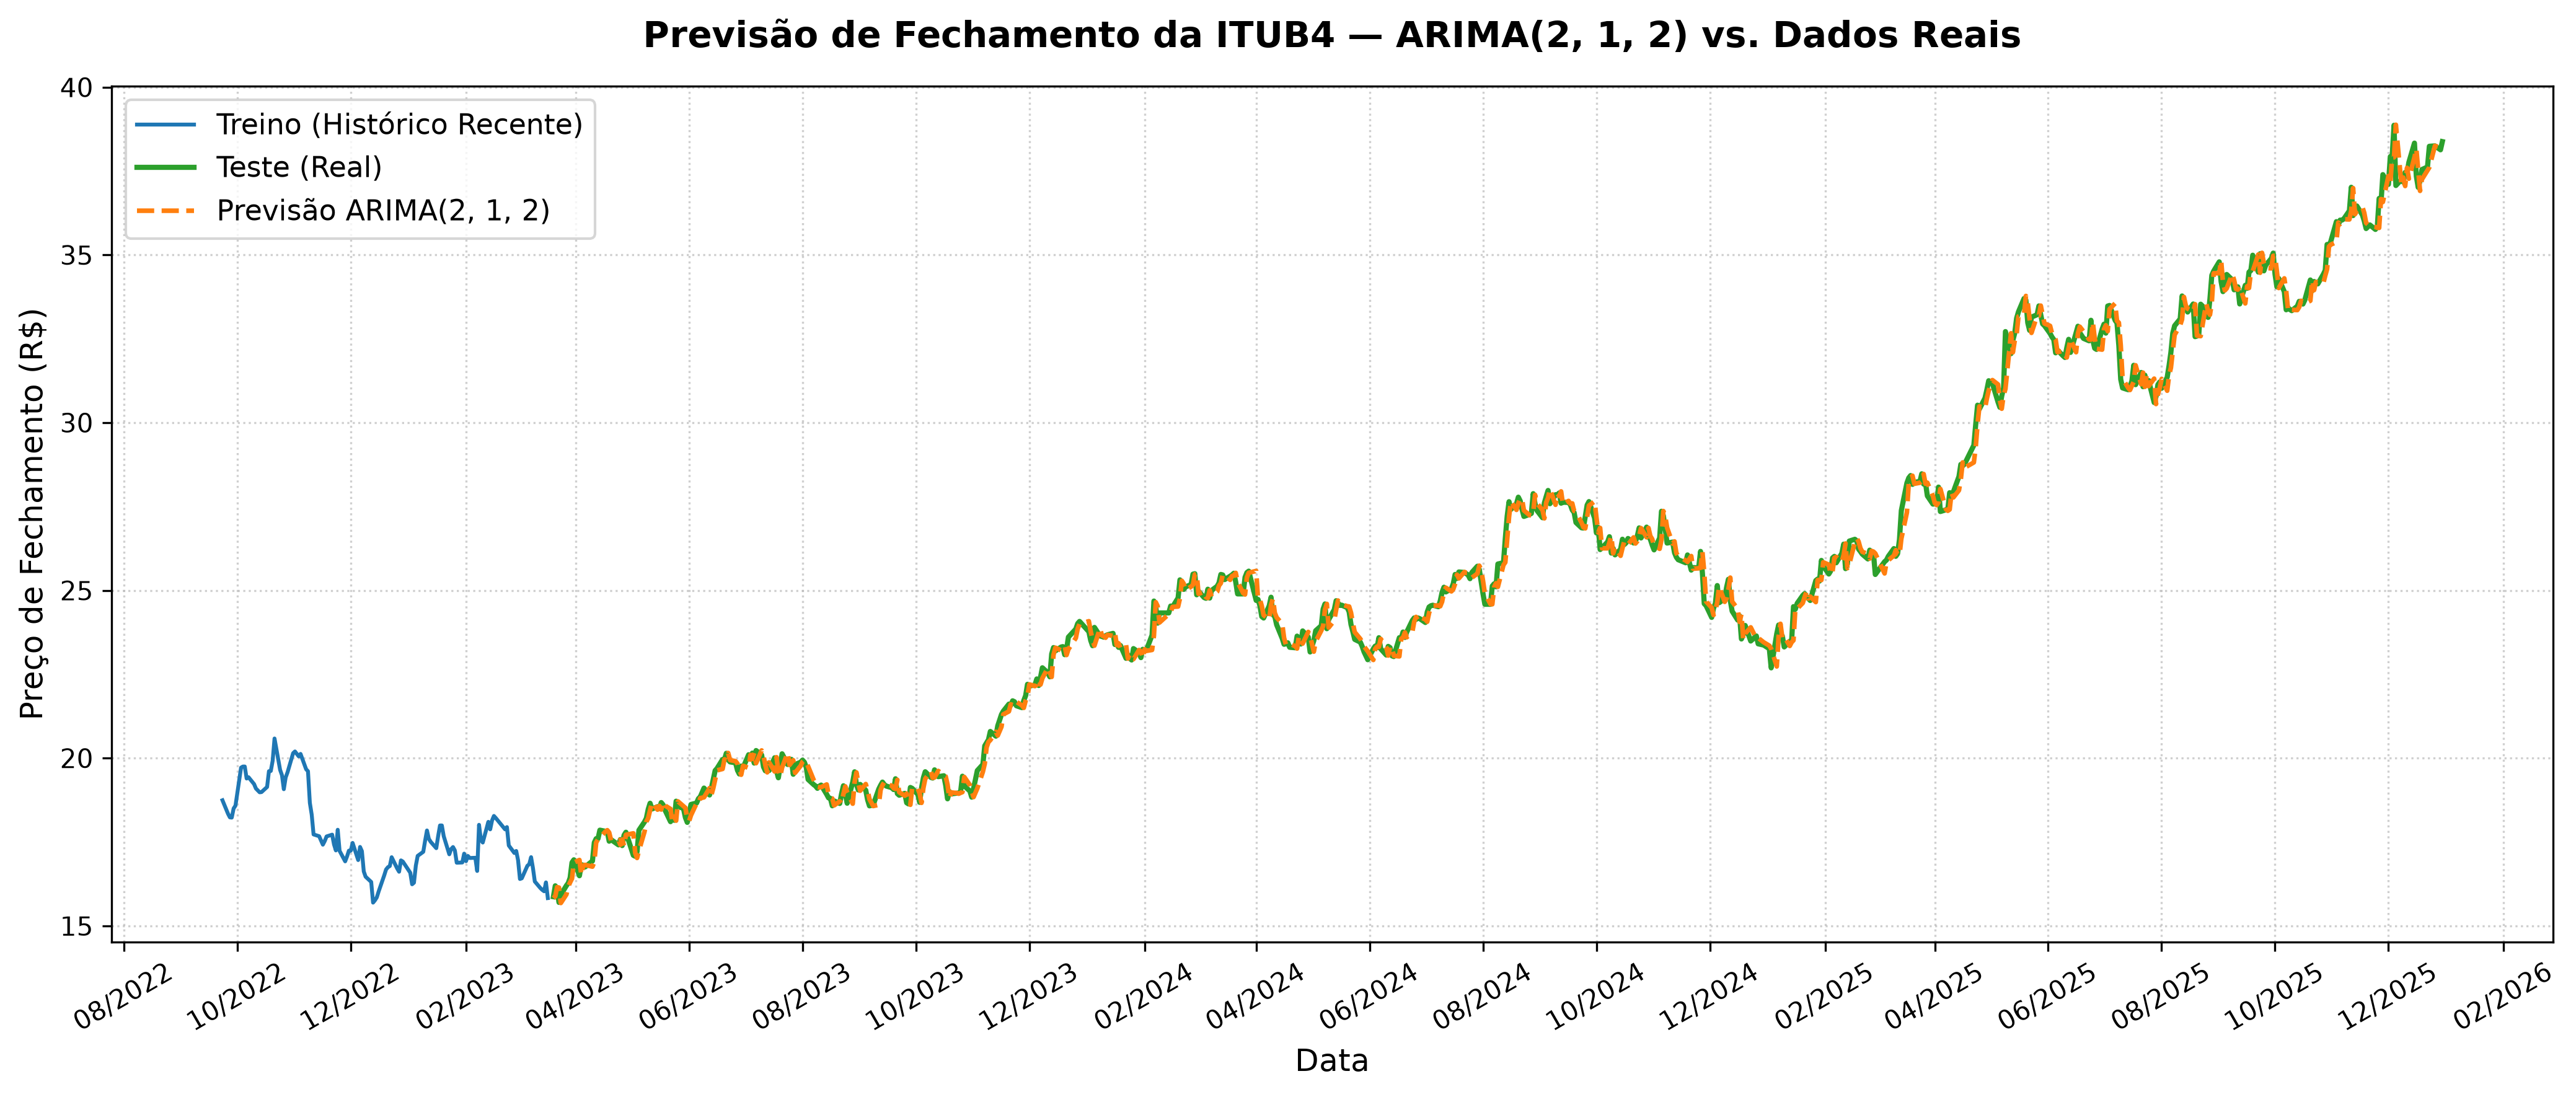

In [5]:
plot_forecast(
    train_itub, test_itub,
    predictions=res_itub["predictions"],
    stock_name="itub",
    model_name=f"ARIMA{res_itub['order']}",
    ticker_label="ITUB4",
)

## XGBooster

In [ ]:
res_xgbooster = run_xgbooster(train_itub, test_itub, "itub")
plot_forecast(
    train_itub, test_itub,
    predictions=res_xgbooster["predictions"],
    stock_name="itub",
    model_name="XGBoost (Tuned)",
    ticker_label="ITUB4",
    company_name="Itaú",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

--- XGBoost ITUB: 37 features, 2740 treino / 696 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits


Trial 30 Complete [00h 00m 03s]
val_loss: 0.0018613683059811592

Best val_loss So Far: 0.0007247189641930163
Total elapsed time: 00h 00m 55s
Melhores hiperparâmetros: {'n_layers': 1, 'units_0': 128, 'dropout_0': 0.4, 'learning_rate': 0.001, 'units_1': 128, 'dropout_1': 0.2, 'units_2': 32, 'dropout_2': 0.0, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 2, 'tuner/round': 2, 'tuner/trial_id': '0013'}
Epoch 1/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0766 - mae: 0.1956 - val_loss: 0.0091 - val_mae: 0.0871
Epoch 2/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0123 - mae: 0.0854 - val_loss: 0.0014 - val_mae: 0.0292
Epoch 3/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0082 - mae: 0.0703 - val_loss: 0.0013 - val_mae: 0.0283
Epoch 4/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0067 - mae: 0.0632 - val_loss: 0.0019 - val_mae: 0.0353
Epoch 5/100
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0056 - mae: 0.0584 - val_loss: 0.0021 - val_mae: 0.03

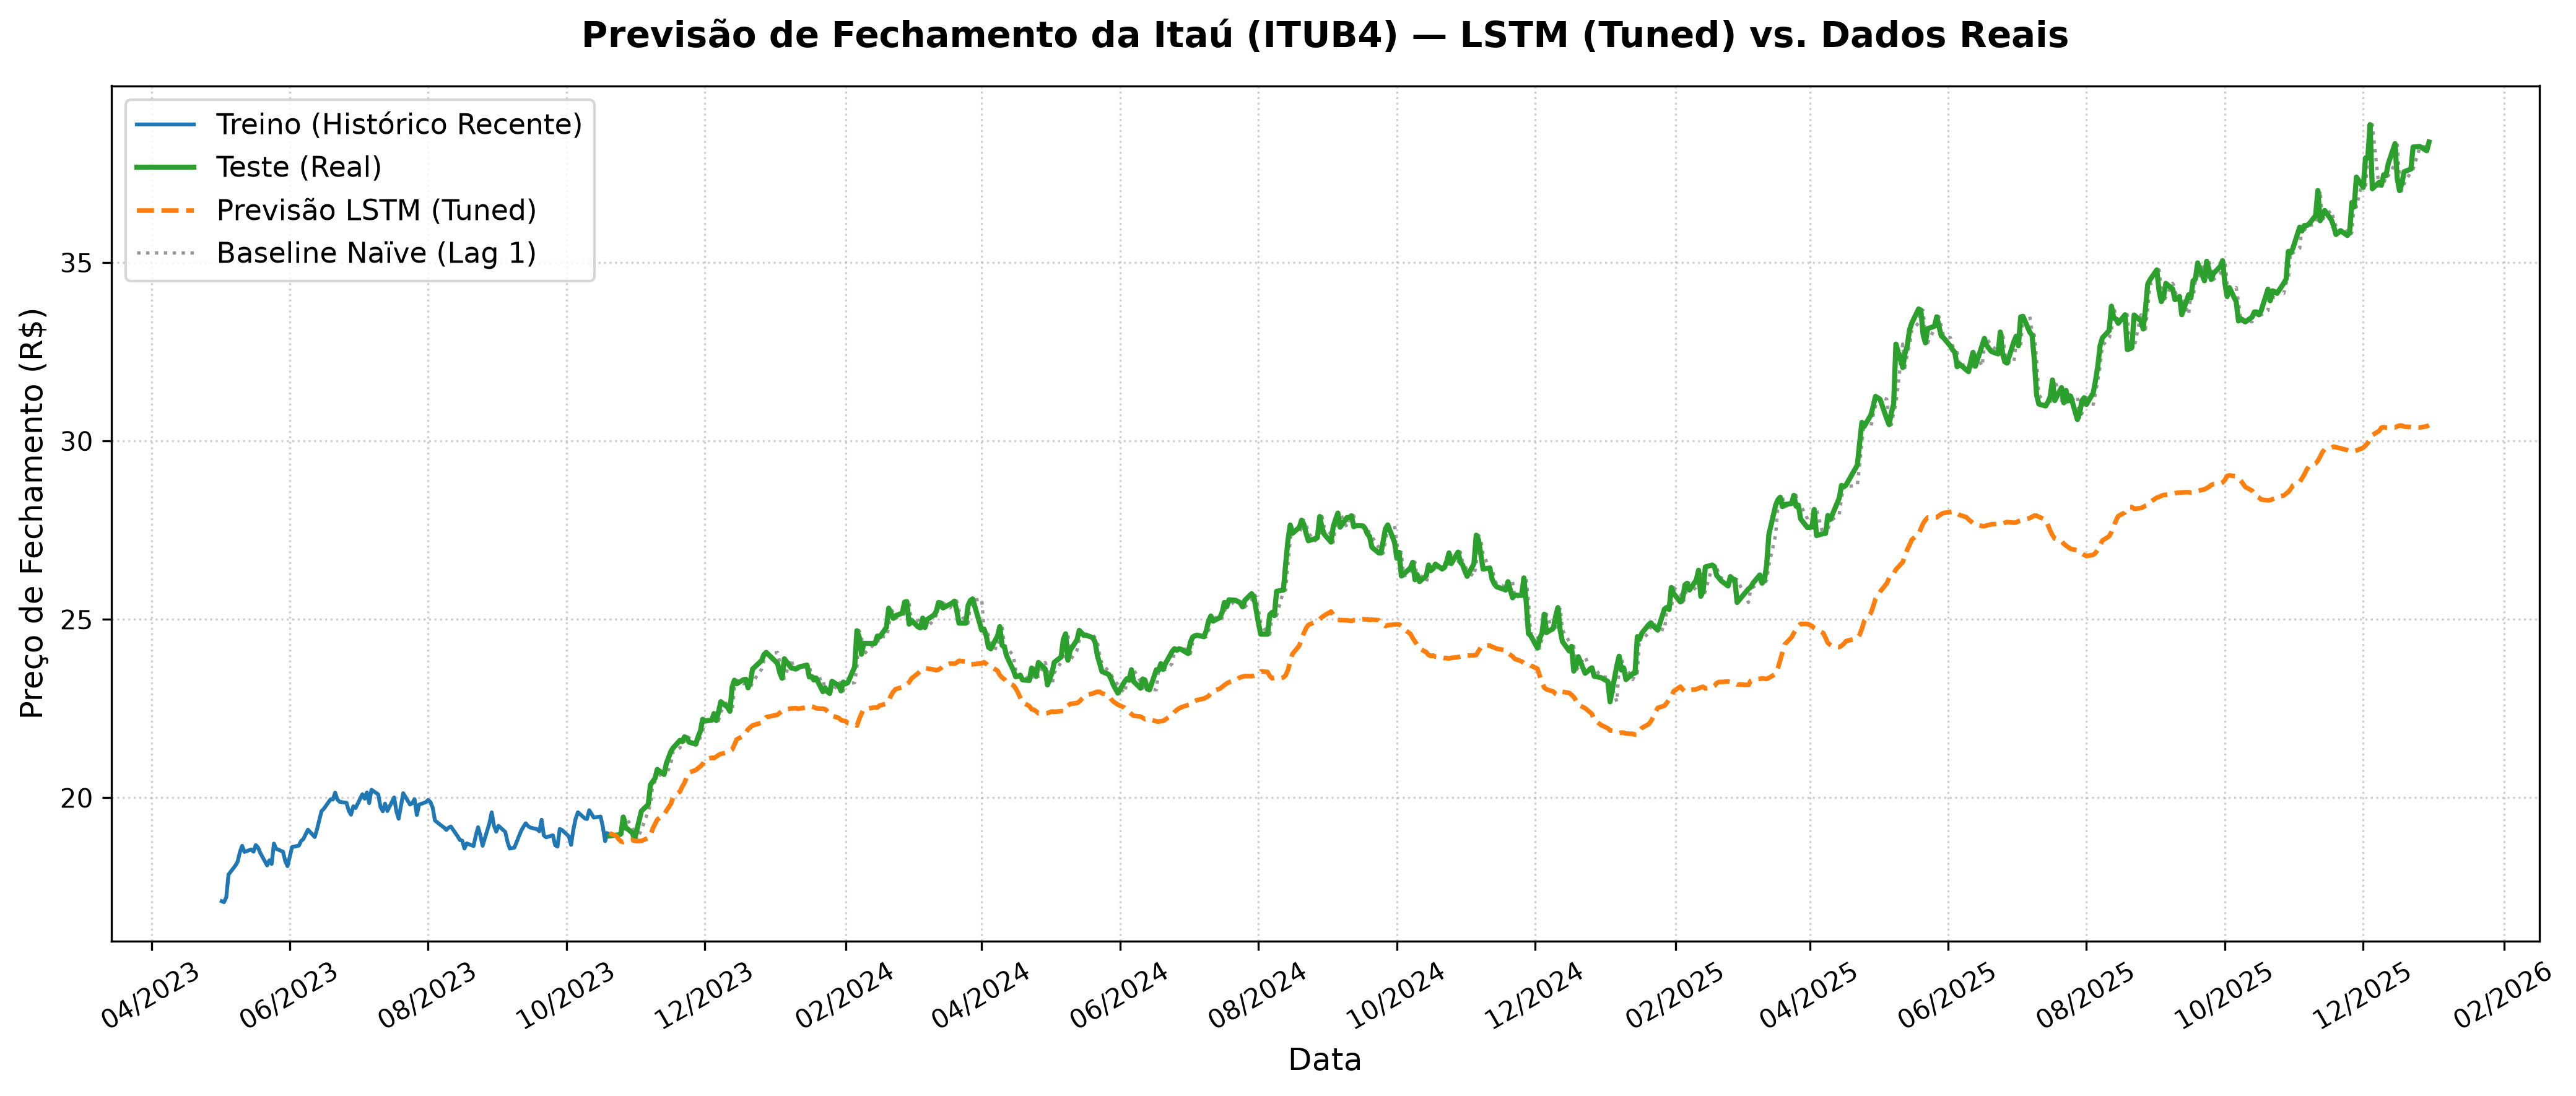

In [ ]:
res_lstm = run_lstm(train_itub, test_itub, "itub", max_epochs=10)
plot_forecast(train_itub, test_itub, res_lstm["predictions"], "itub",
              model_name="LSTM (Tuned)", ticker_label="ITUB4",
              company_name="Itaú", baseline=res_lstm["ontem"])

In [ ]:
tab_itub = explain_variables(res_itub)
tab_itub.head(10)

In [ ]:
tab_itub = explain_variables(res_xgbooster)
tab_itub.head(10)

In [ ]:
tab_itub = explain_variables(res_lstm)
tab_itub.head(10)